In [1]:
import argparse
from rclpy.serialization import deserialize_message
from rosidl_runtime_py.utilities import get_message
from std_msgs.msg import String
from geometry_msgs.msg import PoseStamped
import rosbag2_py
import numpy as np
import matplotlib.pyplot as plt
import motor_msgs
import zed_msgs

In [2]:
def get_metadata(input_bag: str):
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
    return reader.get_metadata()

def read_messages(input_bag: str):
    reader = rosbag2_py.SequentialReader()
    reader.open(
        rosbag2_py.StorageOptions(uri=input_bag, storage_id="mcap"),
        rosbag2_py.ConverterOptions(
            input_serialization_format="cdr", output_serialization_format="cdr"
        ),
    )
    print(reader.get_metadata())

    topic_types = reader.get_all_topics_and_types()

    def typename(topic_name):
        for topic_type in topic_types:
            if topic_type.name == topic_name:
                return topic_type.type
        raise ValueError(f"topic {topic_name} not in bag")

    while reader.has_next():
        topic, data, timestamp = reader.read_next()
        msg_type = get_message(typename(topic))
        msg = deserialize_message(data, msg_type)
        yield topic, msg, timestamp
    del reader

In [4]:
bag_path = "../../../2026_7_29_rosbags/2026_7_29__16_16_40Concrete_wet_3s.bag/2026_7_29__16_16_40Concrete_wet_3s.bag_0.mcap"
metadata = get_metadata(bag_path)
# metadata.topics_with_message_count[2].message_count

# Use this to find out topics and their message counts. 
topics = {name.topic_metadata.name : name.message_count for name in metadata.topics_with_message_count}
print(topics)

{'/robot_description': 1, '/zed/zed_node/pose_with_covariance': 2514, '/zed/zed_node/pose': 2514, '/zed/zed_node/path_odom': 168, '/zed/zed_node/imu/data_raw': 8366, '/zed/zed_node/imu/data': 8366, '/zed/zed_node/odom': 2514, '/joy': 1153, '/vrpn_mocap/rb/accel': 16594, '/vrpn_mocap/rb/twist': 16595, '/vrpn_mocap/rb/pose': 16595, '/dynamic_joint_states': 2134, '/pico_imu': 12892, '/joint_state_broadcaster/transition_event': 0, '/tf': 8249, '/joint_states': 2135, '/odom_in_vicon_frame': 0, '/parameter_events': 0, '/rb_slip_controller/cmd_vel': 299, '/rb_slip_controller/transition_event': 0, '/rosout': 19, '/rb_slip_controller/odom': 2134, '/tf_static': 2}


In [3]:
num_imu_msgs = topics["/pico_imu"]
num_left_currents = topics["/left_motor_currents"]
num_right_currents = topics["/right_motor_currents"]

imu_acc = np.zeros((3, num_imu_msgs))
imu_gyro = np.zeros((3, num_imu_msgs))
imu_timestamps = np.zeros(num_imu_msgs)

left_motor_currents = np.zeros(num_left_currents)
left_motor_timestamps = np.zeros(num_left_currents)

right_motor_currents = np.zeros(num_right_currents)
right_motor_timestamps = np.zeros(num_right_currents)

imu_idx, left_idx, right_idx = 0, 0, 0
for topic, msg, timestamp in read_messages(bag_path):
    time_sec = timestamp * 1e-9  # Convert to seconds
    if topic == "/pico_imu":
        imu_acc[:, imu_idx] = [
            msg.linear_acceleration.x,
            msg.linear_acceleration.y,
            msg.linear_acceleration.z,
        ]
        imu_gyro[:, imu_idx] = [
            msg.angular_velocity.x,
            msg.angular_velocity.y,
            msg.angular_velocity.z,
        ]
        imu_timestamps[imu_idx] = time_sec
        imu_idx += 1
    elif topic == "/left_motor_currents":
        left_motor_currents[left_idx] = msg.data[1]  # or msg.current if it's wrapped
        left_motor_timestamps[left_idx] = time_sec
        left_idx += 1

    elif topic == "/right_motor_currents":
        right_motor_currents[right_idx] = msg.data[1]
        right_motor_timestamps[right_idx] = time_sec
        right_idx += 1


# Match nearest motor current values to each IMU timestamp
def match_nearest(t_query, t_array, values):
    indices = np.searchsorted(t_array, t_query)
    indices = np.clip(indices, 1, len(t_array) - 1)
    left = t_array[indices - 1]
    right = t_array[indices]
    chosen_indices = np.where(np.abs(t_query - left) < np.abs(t_query - right), indices - 1, indices)
    return values[chosen_indices]

matched_left = match_nearest(imu_timestamps, left_motor_timestamps, left_motor_currents)
matched_right = match_nearest(imu_timestamps, right_motor_timestamps, right_motor_currents)
imu_ax = imu_acc[0, :]

# Plotting
plt.figure(figsize=(12, 6))
plt.plot(imu_timestamps, imu_ax, label='IMU Accel X')
plt.plot(imu_timestamps, matched_left, label='Left Motor Current')
plt.plot(imu_timestamps, matched_right, label='Right Motor Current')
plt.xlabel('Time (s)')
plt.ylabel('Value')
plt.legend()
plt.title('IMU Acceleration and Motor Currents Over Time')
plt.grid(True)
plt.tight_layout()
plt.show()


NameError: name 'topics' is not defined

In [5]:
for topic_info in metadata.topics_with_message_count:
    if topic_info.topic_metadata.name == "/zed/zed_node/imu/data_raw":
        topic_name = topic_info.topic_metadata.name
        message_count = topic_info.message_count
        duration = metadata.duration.nanoseconds * 1e-9  # Convert to seconds
        frequency = message_count / duration if duration > 0 else 0
        print(f"Topic: {topic_name}")
        print(f"Total Messages: {message_count}")
        print(f"Bag Duration: {duration:.2f} seconds")
        print(f"Estimated Frequency: {frequency:.2f} Hz")

Topic: /zed/zed_node/imu/data_raw
Total Messages: 4669
Bag Duration: 47.05 seconds
Estimated Frequency: 99.23 Hz


In [9]:
#bag_path = "../../retail_bot_exp_02_03/2025_2_3__17_25_29drive_stop_1.bag-20250204T151843Z-001/2025_2_3__17_25_29drive_stop_1.bag/2025_2_3__17_25_29drive_stop_1.bag_0.mcap"
topic_name = "/rb_slip_controller/cmd_vel"

# Counter to limit the number of messages displayed
count = 0
max_messages = 10  # Change this number if you want more messages

for topic, msg, timestamp in read_messages(bag_path):
    if topic == topic_name:
        print(f"Timestamp: {timestamp}, Message: {msg}")
        count += 1
    if count >= max_messages:
        break



Files:             ../../../2026_1_29_rosbags/2026_1_29__14_02_01Carpet.bag/2026_1_29__14_02_01Carpet.bag_0.mcap
Bag size:          6.7 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          42.032125605s
Start:             Jan 29 2026 19:02:01.651750820 (1769713321.651750820)
End:               Jan 29 2026 19:02:43.683876425 (1769713363.683876425)
Messages:          34879
Topic information: Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJointState | Count: 816 | Serialization Format: cdr
                   Topic: /joint_state_broadcaster/transition_event | Type: lifecycle_msgs/msg/TransitionEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_states | Type: sensor_msgs/msg/JointState | Count: 816 | Serialization Format: cdr
                   Topic: /joy | Type: sensor_msgs/msg/Joy | Count: 631 | Serialization Format: cdr
                   Topic: /odom_in_vicon_frame | Type: geometry_msgs/msg/PoseStamped | Count: 0 | Serializat

In [7]:
topic_name = "/zed/zed_node/pose_with_covariance"

# Counter to limit the number of messages displayed
count = 0
max_messages = 5  # Change this number if you want more messages

for topic, msg, timestamp in read_messages(bag_path):
    if topic == topic_name:
        print(f"Timestamp: {timestamp}, Message: {msg}")
        count += 1
    if count >= max_messages:
        break


Files:             ../../../2025_10_16_rosbags-20251017T151443Z-1-001/2025_10_16_rosbags/2025_10_16__16_04_27Concrete.bag/2025_10_16__16_04_27Concrete.bag_0.mcap
Bag size:          25.9 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          108.642195346s
Start:             Oct 16 2025 20:04:28.480839863 (1760645068.480839863)
End:               Oct 16 2025 20:06:17.123035209 (1760645177.123035209)
Messages:          92792
Topic information: Topic: /rb_slip_controller/cmd_vel | Type: twist_slip_msg/msg/TwistSlipStamped | Count: 294 | Serialization Format: cdr
                   Topic: /odom_in_vicon_frame | Type: geometry_msgs/msg/PoseStamped | Count: 0 | Serialization Format: cdr
                   Topic: /pico_imu | Type: sensor_msgs/msg/Imu | Count: 13457 | Serialization Format: cdr
                   Topic: /joy | Type: sensor_msgs/msg/Joy | Count: 1606 | Serialization Format: cdr
                   Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJoin

In [3]:
import os
import glob
import numpy as np

def process_bag(bag_path, output_dir="../Sensor_data"):
    """Process a single ROS bag and save as .npz"""
    metadata = get_metadata(bag_path)
    topics = {name.topic_metadata.name: name.message_count for name in metadata.topics_with_message_count}

    num_imu_msgs = topics["/pico_imu"]
    num_vicon_msgs = topics["/vrpn_mocap/rb/pose"]
    num_vicon_twist_msgs = topics["/vrpn_mocap/rb/twist"]
    num_odom_msgs = topics["/rb_slip_controller/odom"]
    num_zed_msgs = topics.get("/zed/zed_node/pose_with_covariance", 0)
    num_zed_twist_msgs = topics.get("/zed/zed_node/odom", 0)
    num_encoder_msgs = topics["/dynamic_joint_states"]
    num_cmd = topics.get("/rb_slip_controller/cmd_vel", 0)

    # Preallocate
    imu_acc = np.zeros((3, num_imu_msgs))
    imu_gyro = np.zeros((3, num_imu_msgs))
    imu_timestamps = np.zeros(num_imu_msgs)

    vicon_poses = np.zeros((7, num_vicon_msgs))
    vicon_timestamps = np.zeros(num_vicon_msgs)

    vicon_twists = np.zeros((6, num_vicon_twist_msgs))
    vicon_twist_timestamps = np.zeros(num_vicon_twist_msgs)

    odom_poses = np.zeros((7, num_odom_msgs))
    odom_twists = np.zeros((6, num_odom_msgs))
    odom_timestamps = np.zeros(num_odom_msgs)
    
    if num_cmd > 0:
        cmd_vel = np.zeros(num_cmd)
        cmd_timestamps = np.zeros(num_cmd)

    if num_zed_twist_msgs > 0:
        zed_twists = np.zeros((6, num_zed_twist_msgs))
        zed_twist_timestamps = np.zeros(num_zed_twist_msgs)

    if num_zed_msgs > 0:
        zed_poses = np.zeros((7, num_zed_msgs))
        zed_timestamps = np.zeros(num_zed_msgs)

    encoder_counts = np.zeros((4, num_encoder_msgs))
    encoder_timestamps = np.zeros(num_encoder_msgs)

    imu_idx, vicon_idx, odom_idx, vicon_twist_idx, encoder_idx, zed_idx, zed_twist_idx, cmd_vel_idx = 0, 0, 0, 0, 0, 0, 0, 0

    for topic, msg, timestamp in read_messages(bag_path):
        time_sec = timestamp * 1e-9

        if topic == "/pico_imu":
            imu_acc[:, imu_idx] = [msg.linear_acceleration.x,
                                   msg.linear_acceleration.y,
                                   msg.linear_acceleration.z]
            imu_gyro[:, imu_idx] = [msg.angular_velocity.x,
                                    msg.angular_velocity.y,
                                    msg.angular_velocity.z]
            imu_timestamps[imu_idx] = time_sec
            imu_idx += 1

        elif topic == "/vrpn_mocap/rb/pose":
            vicon_poses[:, vicon_idx] = [msg.pose.position.x,
                                         msg.pose.position.y,
                                         msg.pose.position.z,
                                         msg.pose.orientation.w,
                                         msg.pose.orientation.x,
                                         msg.pose.orientation.y,
                                         msg.pose.orientation.z]
            vicon_timestamps[vicon_idx] = time_sec
            vicon_idx += 1

        elif topic == "/vrpn_mocap/rb/twist":
            vicon_twists[:, vicon_twist_idx] = [msg.twist.linear.x,
                                                msg.twist.linear.y,
                                                msg.twist.linear.z,
                                                msg.twist.angular.x,
                                                msg.twist.angular.y,
                                                msg.twist.angular.z]
            vicon_twist_timestamps[vicon_twist_idx] = time_sec
            vicon_twist_idx += 1

        elif topic == "/rb_slip_controller/odom":
            odom_poses[:, odom_idx] = [msg.pose.pose.position.x,
                                       msg.pose.pose.position.y,
                                       msg.pose.pose.position.z,
                                       msg.pose.pose.orientation.w,
                                       msg.pose.pose.orientation.x,
                                       msg.pose.pose.orientation.y,
                                       msg.pose.pose.orientation.z]
            odom_twists[:, odom_idx] = [msg.twist.twist.linear.x,
                                        msg.twist.twist.linear.y,
                                        msg.twist.twist.linear.z,
                                        msg.twist.twist.angular.x,
                                        msg.twist.twist.angular.y,
                                        msg.twist.twist.angular.z]
            odom_timestamps[odom_idx] = time_sec
            odom_idx += 1

        elif topic == "/zed/zed_node/odom" and num_zed_twist_msgs > 0:
            zed_twists[:, zed_twist_idx] = [msg.twist.twist.linear.x,
                                            msg.twist.twist.linear.y,
                                            msg.twist.twist.linear.z,
                                            msg.twist.twist.angular.x,
                                            msg.twist.twist.angular.y,
                                            msg.twist.twist.angular.z]
            zed_twist_timestamps[zed_twist_idx] = time_sec
            zed_twist_idx += 1

        elif topic == "/zed/zed_node/pose_with_covariance" and num_zed_msgs > 0:
            zed_poses[:, zed_idx] = [msg.pose.pose.position.x,
                                     msg.pose.pose.position.y,
                                     msg.pose.pose.position.z,
                                     msg.pose.pose.orientation.w,
                                     msg.pose.pose.orientation.x,
                                     msg.pose.pose.orientation.y,
                                     msg.pose.pose.orientation.z]
            zed_timestamps[zed_idx] = time_sec
            zed_idx += 1

        elif topic == "/dynamic_joint_states":
            for i, interface_val in enumerate(msg.interface_values):
                enc_index = interface_val.interface_names.index("encoder_count")
                encoder_counts[i, encoder_idx] = interface_val.values[enc_index]
            encoder_timestamps[encoder_idx] = time_sec
            encoder_idx += 1

        elif topic == "/rb_slip_controller/cmd_vel":
            cmd_vel[cmd_vel_idx] = msg.twist.linear.x
            cmd_timestamps[cmd_vel_idx] = time_sec
            cmd_vel_idx += 1

    # Save .npz
    base_name = os.path.basename(bag_path).replace(".bag", "").replace(".mcap", "")
    out_file = os.path.join(output_dir, f"{base_name}.npz")

    save_dict = dict(
        imu_acc=imu_acc, imu_gyro=imu_gyro, imu_timestamps=imu_timestamps,
        vicon_poses=vicon_poses, vicon_timestamps=vicon_timestamps,
        vicon_twists=vicon_twists, vicon_twist_timestamps=vicon_twist_timestamps,
        odom_poses=odom_poses, odom_twists=odom_twists, odom_timestamps=odom_timestamps,
        encoder_counts=encoder_counts, encoder_timestamps=encoder_timestamps
    )

    if num_zed_msgs > 0:
        save_dict["zed_poses"] = zed_poses
        save_dict["zed_timestamps"] = zed_timestamps

    if num_zed_twist_msgs > 0:
        save_dict["zed_twists"] = zed_twists
        save_dict["zed_twist_timestamps"] = zed_twist_timestamps
        
    if num_cmd > 0:
        save_dict["cmd_vel"] = cmd_vel
        save_dict["cmd_timestamps"] = cmd_timestamps

    np.savez(out_file, **save_dict)
    print(f"Saved {out_file}")


# === Loop through all rosbags in folder ===
rosbag_dir = "../../../2026_8_6_rosbags/"
mcap_files = glob.glob(os.path.join(rosbag_dir, "**/*.mcap"), recursive=True)

for mcap_file in mcap_files:
    process_bag(mcap_file)


Files:             ../../../2026_8_6_rosbags/2026_8_6__16_50_08Carpet_2s.bag/2026_8_6__16_50_08Carpet_2s.bag_0.mcap
Bag size:          41.2 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          44.237218882s
Start:             Aug  6 2026 20:50:09.566505172 (1786049409.566505172)
End:               Aug  6 2026 20:50:53.803724054 (1786049453.803724054)
Messages:          52180
Topic information: Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJointState | Count: 1154 | Serialization Format: cdr
                   Topic: /joint_state_broadcaster/transition_event | Type: lifecycle_msgs/msg/TransitionEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_states | Type: sensor_msgs/msg/JointState | Count: 1154 | Serialization Format: cdr
                   Topic: /joy | Type: sensor_msgs/msg/Joy | Count: 610 | Serialization Format: cdr
                   Topic: /odom_in_vicon_frame | Type: geometry_msgs/msg/PoseStamped | Count: 0 | Seri

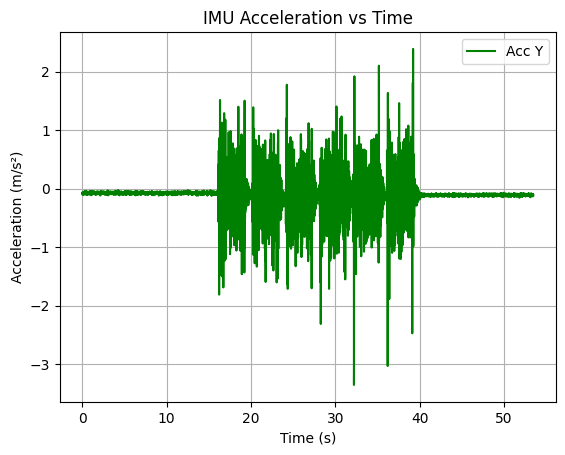

In [6]:
# Plot the IMU accelerations
#plt.figure
#plt.plot(imu_timestamps, imu_acc[0, :], label="Acc X", color='r')
plt.figure
plt.plot(imu_timestamps, imu_acc[1, :], label="Acc Y", color='g')
#plt.figure
#plt.plot(timestamps, imu_acc[2, :], label="Acc Z", color='b')

plt.xlabel("Time (s)")
plt.ylabel("Acceleration (m/s²)")
plt.title("IMU Acceleration vs Time")
plt.legend()
plt.grid()
plt.show()



Files:             ../../../2026_6_26_rosbags/2026_6_26__14_13_42Board_zed.bag/2026_6_26__14_13_42Board_zed.bag_0.mcap
Bag size:          22.8 MiB
Storage id:        mcap
ROS Distro:        jazzy
Duration:          47.053888952s
Start:             Jun 26 2026 18:13:42.612160397 (1782497622.612160397)
End:               Jun 26 2026 18:14:29.666049349 (1782497669.666049349)
Messages:          50768
Topic information: Topic: /dynamic_joint_states | Type: control_msgs/msg/DynamicJointState | Count: 1243 | Serialization Format: cdr
                   Topic: /joint_state_broadcaster/transition_event | Type: lifecycle_msgs/msg/TransitionEvent | Count: 0 | Serialization Format: cdr
                   Topic: /joint_states | Type: sensor_msgs/msg/JointState | Count: 1244 | Serialization Format: cdr
                   Topic: /joy | Type: sensor_msgs/msg/Joy | Count: 715 | Serialization Format: cdr
                   Topic: /odom_in_vicon_frame | Type: geometry_msgs/msg/PoseStamped | Count: 0 | S

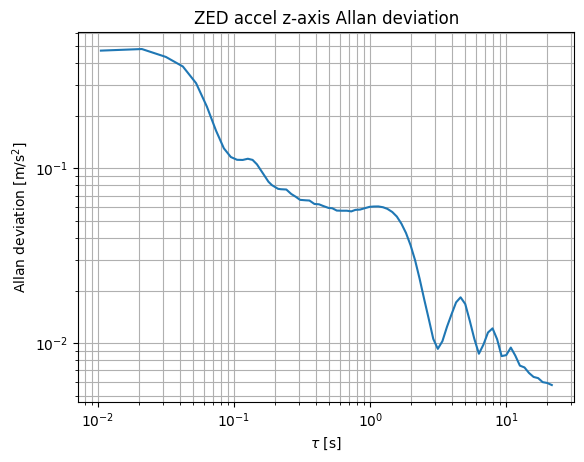

Gyro z-axis
Angular random walk / white noise N: 1.7016e-02 rad/s/sqrt(Hz)
Bias instability B:                  1.4388e-03 rad/s
Bias random walk K:                  6.3658e-02 rad/s/sqrt(s)


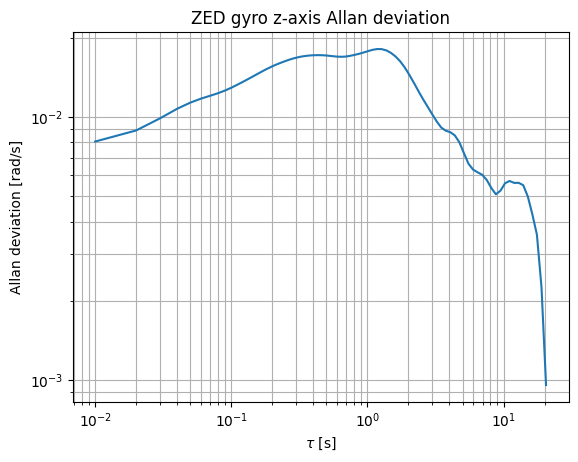

In [7]:
import numpy as np
import matplotlib.pyplot as plt

def allan_deviation_rate_signal(x, fs, max_num_m=100):
    """
    Allan deviation for rate-like IMU signals.

    For gyro:
        x = angular velocity [rad/s]
        integrated signal = angle [rad]

    For accelerometer:
        x = acceleration [m/s^2]
        integrated signal = velocity [m/s]

    Output adev has same units as x.
    """

    x = np.asarray(x).squeeze()
    x = x[np.isfinite(x)]

    dt = 1.0 / fs
    L = len(x)

    # Integrate rate signal
    x_integrated = np.cumsum(x) * dt

    # Cluster sizes
    max_m = 2 ** int(np.floor(np.log2(L / 2)))
    m = np.logspace(np.log10(1), np.log10(max_m), max_num_m).astype(int)
    m = np.unique(m)

    tau = m * dt
    avar = np.zeros(len(m))

    for i, mi in enumerate(m):
        if L - 2 * mi <= 0:
            avar[i] = np.nan
            continue

        diff2 = (
            x_integrated[2 * mi:L]
            - 2 * x_integrated[mi:L - mi]
            + x_integrated[:L - 2 * mi]
        )

        avar[i] = np.sum(diff2 ** 2) / (2 * tau[i] ** 2 * (L - 2 * mi))

    valid = np.isfinite(avar) & (avar > 0)
    return tau[valid], np.sqrt(avar[valid])

def estimate_allan_coefficients(tau, adev):
    """
    Estimate:
    N  = white noise / random walk coefficient
    B  = bias instability
    K  = bias random walk coefficient

    For gyro input in rad/s:
        N units: rad/s/sqrt(Hz), equivalent rad/sqrt(s)
        B units: rad/s
        K units: rad/s/sqrt(s)

    For accel input in m/s^2:
        N units: m/s^2/sqrt(Hz), equivalent m/s/sqrt(s)
        B units: m/s^2
        K units: m/s^2/sqrt(s)
    """

    log_tau = np.log10(tau)
    log_adev = np.log10(adev)

    slopes = np.gradient(log_adev, log_tau)

    # White noise / random walk: slope approximately -1/2
    white_idx = np.argsort(np.abs(slopes + 0.5))[:5]
    N = np.median(adev[white_idx] * np.sqrt(tau[white_idx]))

    # Bias instability: flat region, approximately minimum / 0.664
    B = np.min(adev) / 0.664

    # Bias random walk: slope approximately +1/2
    rw_idx = np.argsort(np.abs(slopes - 0.5))[:5]
    K = np.median(adev[rw_idx] * np.sqrt(3.0 / tau[rw_idx]))

    return N, B, K, slopes

imu_acc = []
imu_gyr = []
imu_t = []

for topic, msg, timestamp in read_messages(bag_path):
    if topic == "/zed/zed_node/imu/data_raw":
        imu_acc.append([
            msg.linear_acceleration.x,
            msg.linear_acceleration.y,
            msg.linear_acceleration.z
        ])

        imu_gyr.append([
            msg.angular_velocity.x,
            msg.angular_velocity.y,
            msg.angular_velocity.z
        ])

        imu_t.append(timestamp * 1e-9)  # bag timestamp in seconds

imu_acc = np.array(imu_acc).T  # shape: 3 x N, units: m/s^2
imu_gyr = np.array(imu_gyr).T  # shape: 3 x N, units: rad/s
imu_t = np.array(imu_t)

Fs = 1.0 / np.median(np.diff(imu_t))
t0 = 1.0 / Fs

print("imu_acc shape:", imu_acc.shape)
print("imu_gyr shape:", imu_gyr.shape)
print("Estimated IMU Fs:", Fs)

axis = 2  # z-axis

tau, adev = allan_deviation_rate_signal(imu_acc[axis, :], Fs)
N_acc, B_acc, K_acc, slopes = estimate_allan_coefficients(tau, adev)

print("Accel z-axis")
print(f"Velocity random walk / white noise N: {N_acc:.4e} m/s^2/sqrt(Hz)")
print(f"Bias instability B:                 {B_acc:.4e} m/s^2")
print(f"Bias random walk K:                 {K_acc:.4e} m/s^2/sqrt(s)")

plt.figure()
plt.loglog(tau, adev)
plt.xlabel(r"$\tau$ [s]")
plt.ylabel(r"Allan deviation [m/s$^2$]")
plt.title("ZED accel z-axis Allan deviation")
plt.grid(True, which="both")
plt.show()

# imu_gyr should be in rad/s
axis = 2  # z-axis

tau, adev = allan_deviation_rate_signal(imu_gyr[axis, :], fs)
N_gyr, B_gyr, K_gyr, slopes = estimate_allan_coefficients(tau, adev)

print("Gyro z-axis")
print(f"Angular random walk / white noise N: {N_gyr:.4e} rad/s/sqrt(Hz)")
print(f"Bias instability B:                  {B_gyr:.4e} rad/s")
print(f"Bias random walk K:                  {K_gyr:.4e} rad/s/sqrt(s)")

plt.figure()
plt.loglog(tau, adev)
plt.xlabel(r"$\tau$ [s]")
plt.ylabel("Allan deviation [rad/s]")
plt.title("ZED gyro z-axis Allan deviation")
plt.grid(True, which="both")
plt.show()

In [16]:
import sqlite3
bagfile1 = "../../logging/2025_2_3_rosbags/2025_2_3__18_00_30sin_drive_0to6RPM.bag/"

conn = sqlite3.connect(bagfile1)
cursor = conn.cursor()

cursor.execute("SELECT name FROM sqlite_master WHERE type='table';")
tables = cursor.fetchall()
print(tables)

OperationalError: unable to open database file